# Охлаждение процессора через металлический куб

**Развитие задачи 16: трёхмерное уравнение Лапласа и теплообмен с водой.**

Процессор передаёт мощность $P$ центральному квадратному участку нижней грани куба.
Выбранные грани отдают тепло воде через теплообмен с коэффициентом $\alpha$.
Температура воды $T_{\text{в}}$ постоянна, а температура металлических стенок **не задана и вычисляется**.
Остальная поверхность теплоизолирована. Нужно найти установившееся поле температуры и сравнить
разные расположения охлаждаемых граней и интенсивности теплообмена.

Учебные параметры: $L=5$ см, $a=3$ см, $P=200$ Вт, $\lambda=200$ Вт/(м·К),
$T_{\text{в}}=20^\circ C$, $\alpha=2000$ Вт/(м²·К).
Коэффициент $\alpha$ выбран для исследования и не является характеристикой конкретного кулера.

Внутри однородного куба тепло не выделяется. Контакт с процессором идеальный.
Вода во всех охлаждаемых гранях имеет одну температуру; её нагрев и движение не рассчитываются.
Под температурой процессора понимаем температуру его поверхности контакта с кубом.

Зависимости: **NumPy и Matplotlib**. Выполнять ячейки сверху вниз.
Самые затратные части — Якоби, подбор релаксации и измельчение сетки.

## 1. Математическая постановка

Ось $z$ направлена вверх. Внутри куба $0<x,y,z<L$:
$$T_{xx}+T_{yy}+T_{zz}=0.$$

На нижней грани участок нагрева:
$$H=\{z=0,\ (L-a)/2<x<(L+a)/2,\ (L-a)/2<y<(L+a)/2\}.$$

На участке контакта с процессором задан равномерный поток внутрь куба:
$$-\lambda T_z=P/a^2\quad\text{на }H.$$
На охлаждаемых гранях задано **граничное условие третьего рода (Робина)**:
$$-\lambda\frac{\partial T}{\partial n}
=\alpha(T_{\text{ст}}-T_{\text{в}}).$$
Здесь $n$ — внешняя нормаль, $T_{\text{ст}}$ — неизвестная температура стенки,
$\alpha>0$ — коэффициент теплоотдачи, Вт/(м²·К). Чем горячее стенка относительно воды, тем больше поток.
На остальных участках: $\partial T/\partial n=0$.

Мощность теплоотвода не задаётся независимо от температуры. Она получается из решения;
в стационарном режиме суммарный теплоотвод должен равняться мощности процессора.
Температура воды фиксирует абсолютный температурный уровень, поэтому решение однозначно.

Четыре варианта: верхняя грань; одна боковая; две противоположные боковые;
две соседние боковые. Первые два имеют одинаковую площадь охлаждения, последние два — тоже.
При сравнении всех случаев $\alpha$ и температура воды одинаковы.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
L, a, P = 0.05, 0.03, 200.0       # м, м, Вт
lam, T_water = 200.0, 20.0            # Вт/(м·К), °C
alpha = 2000.0                  # Вт/(м²·К), интенсивность теплообмена с водой
N, eps = 20, 1e-8                # число ячеек вдоль ребра и допуск невязки

cases = {
    'Верхняя': ['z+'],
    'Одна боковая': ['x-'],
    'Две противоположные': ['x-', 'x+'],
    'Две соседние': ['x-', 'y-'],
}

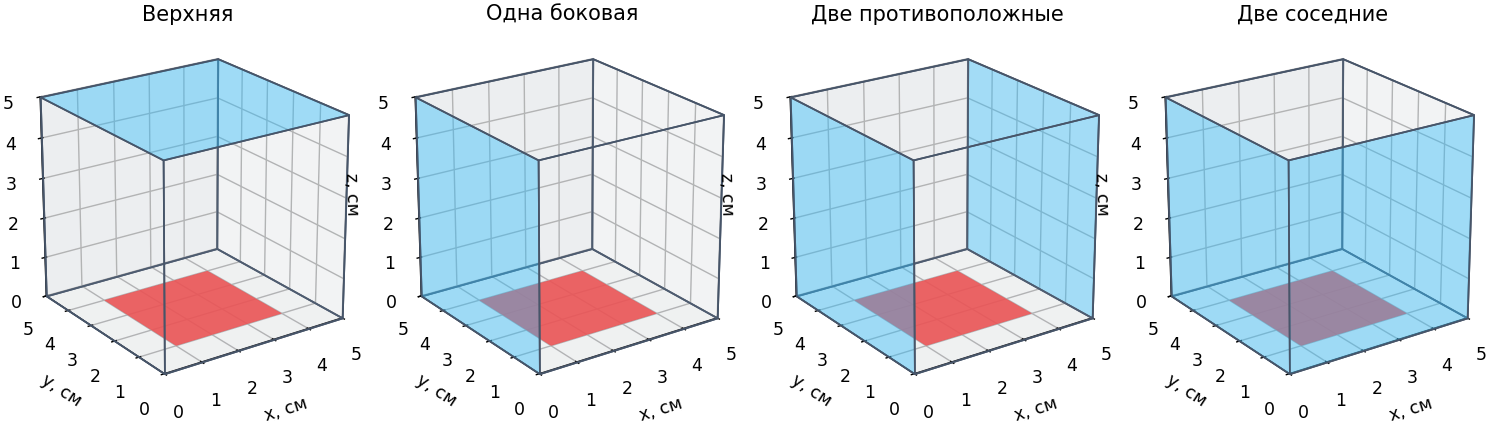

In [2]:
# Схема куба. Голубые грани обмениваются теплом с водой, красный квадрат нагревается.
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

s = L * 100
vertices = {
    'x-': [(0,0,0), (0,s,0), (0,s,s), (0,0,s)],
    'x+': [(s,0,0), (s,s,0), (s,s,s), (s,0,s)],
    'y-': [(0,0,0), (s,0,0), (s,0,s), (0,0,s)],
    'y+': [(0,s,0), (s,s,0), (s,s,s), (0,s,s)],
    'z-': [(0,0,0), (s,0,0), (s,s,0), (0,s,0)],
    'z+': [(0,0,s), (s,0,s), (s,s,s), (0,s,s)],
}
lo, hi = (L-a)*50, (L+a)*50
heater = [(lo,lo,0), (hi,lo,0), (hi,hi,0), (lo,hi,0)]
fig = plt.figure(figsize=(12, 3.4), layout='constrained')
for n, (name, faces) in enumerate(cases.items(), 1):
    ax = fig.add_subplot(1, 4, n, projection='3d')
    for face, polygon in vertices.items():
        cooled = face in faces
        ax.add_collection3d(Poly3DCollection([polygon], edgecolor='#475569',
            facecolor='#38bdf8' if cooled else '#cbd5e1', alpha=.45 if cooled else .06))
    ax.add_collection3d(Poly3DCollection([heater], facecolor='#ef4444', alpha=.9))
    ax.set(xlim=(0,s), ylim=(0,s), zlim=(0,s), title=name,
           xlabel='x, см', ylabel='y, см', zlabel='z, см')
    ax.set_box_aspect((1,1,1))
    ax.view_init(elev=22, azim=-125)
plt.show()

## 2. Разностная схема с тепловым балансом

Куб разделён на $N^3$ ячеек, $h=L/N$. Температуры ищем **в центрах ячеек**.
Баланс потоков (метод конечных объёмов) внутри области даёт обычную семиточечную схему:
$$6T_{ijk}=T_{i-1,j,k}+T_{i+1,j,k}+T_{i,j-1,k}+T_{i,j+1,k}+T_{i,j,k-1}+T_{i,j,k+1}.$$
Мощность между соседними ячейками: $Q_{i\to j}=\lambda h(T_i-T_j)$.

**Поток через охлаждаемую поверхность.** Между центром ячейки и водой есть два последовательных
тепловых сопротивления: теплопроводность на расстоянии $h/2$ и теплоотдача от стенки к воде:
$$R_{\text{яч-в}}=\frac{h/2}{\lambda h^2}+\frac{1}{\alpha h^2}.$$
Поэтому для граничной площадки ячейки
$$Q_{\text{яч-в}}=\frac{T_i-T_{\text{в}}}{R_{\text{яч-в}}}
=\lambda h\beta(T_i-T_{\text{в}}),\qquad
\boxed{\beta=\frac{1}{1/2+\lambda/(\alpha h)}}.$$
Просто подставлять температуру центра ячейки вместо температуры стенки в закон теплоотдачи нельзя:
между ними есть расстояние $h/2$.

При $\alpha\to\infty$ имеем $\beta\to2$: получается прежний случай $T_{\text{ст}}=T_{\text{в}}$.
При малом $\alpha$ имеем $\beta\approx\alpha h/\lambda$: теплообмен с водой ограничивает охлаждение.

Для $u=T-T_{\text{в}}$ баланс любой ячейки:
$$d_i u_i-\sum_{j\in\mathcal N_i}u_j=b_i,\qquad
\boxed{d_i=\#\mathcal N_i+\beta m_i},\qquad b_i=\frac{p_i}{\lambda h}.$$
Здесь $m_i$ — число охлаждаемых наружных граней ячейки, $\mathcal N_i$ — соседние ячейки,
$p_i$ — поступающая мощность процессора (ноль, кроме участка нагрева).
Мощности определяются по пересечению ячеек с площадью процессора, поэтому их сумма равна $P$.
В коде массивы хранятся в порядке **[x, y, z]**.

In [3]:
def face_slice(face):
    s = [slice(None)] * 3
    s['xyz'.index(face[0])] = 0 if face[1] == '-' else -1
    return tuple(s)


def cooling_weight(h, alpha):
    if not alpha > 0:
        raise ValueError('Нужно alpha > 0: при отсутствии теплоотвода стационарного решения нет')
    # alpha = np.inf используется для проверки прежнего предельного случая.
    return 1.0 / (0.5 + lam/(alpha*h))


def make_grid(N, faces, alpha):
    if N < 2 or int(N) != N or not faces:
        raise ValueError('Нужно целое N >= 2 и хотя бы одна охлаждаемая грань')
    if len(set(faces)) != len(faces) or not set(faces) <= {'x-', 'x+', 'y-', 'y+', 'z+'}:
        raise ValueError('Допустимы разные грани x-, x+, y-, y+, z+; нижняя грань нагревается')
    h = L / N
    edges = np.linspace(0, L, N + 1)
    # Пересечение каждой ячейки с квадратом процессора.
    overlap = np.maximum(0, np.minimum(edges[1:], (L+a)/2)
                         - np.maximum(edges[:-1], (L-a)/2))
    power = P * np.outer(overlap, overlap) / a**2
    d = np.zeros((N, N, N))
    for axis in range(3):
        s1, s2 = [slice(None)] * 3, [slice(None)] * 3
        s1[axis], s2[axis] = slice(None, -1), slice(1, None)
        d[tuple(s1)] += 1
        d[tuple(s2)] += 1
    for face in faces:
        d[face_slice(face)] += cooling_weight(h, alpha)
    b = np.zeros_like(d)
    b[:, :, 0] = power / (lam*h)
    parity = np.indices(d.shape).sum(axis=0) % 2
    return h, d, b, power, parity


def neighbors(u):
    s = np.zeros_like(u)
    s[1:, :, :] += u[:-1, :, :]
    s[:-1, :, :] += u[1:, :, :]
    s[:, 1:, :] += u[:, :-1, :]
    s[:, :-1, :] += u[:, 1:, :]
    s[:, :, 1:] += u[:, :, :-1]
    s[:, :, :-1] += u[:, :, 1:]
    return s


def residual(u, d, b):
    return np.max(np.abs(b + neighbors(u) - d*u)) / np.max(np.abs(b))

## 3. Итерационные методы

**Якоби:** одновременно вычисляем все новые температуры по старым значениям.

**Зейдель:** используем шахматную нумерацию — сначала обновляем ячейки с чётной суммой $i+j+k$,
затем с нечётной. Все соседи имеют другой цвет, поэтому второй проход уже использует обновлённые значения.
Это метод Зейделя с другой нумерацией неизвестных, а не лексикографический обход из учебника.
Одна итерация включает оба прохода.

**Верхняя релаксация (SOR):** тот же обход, но обновление имеет вид
$$u_i\leftarrow u_i+\omega\left(\frac{\sum_j u_j+b_i}{d_i}-u_i\right),\quad 0<\omega<2.$$
При $\omega=1$ получается Зейдель. Параметр $\omega$ соответствует параметру $\tau$ в задаче 16.

Для всех методов начальное приближение $u=0$, критерий остановки одинаков:
$$r=\frac{\|b-Au\|_\infty}{\|b\|_\infty}<\varepsilon.$$
Это относительная невязка СЛАУ; она не равна относительной погрешности температуры.

**Почему методы сходятся.** Матрица симметрична и положительно определена:
$$u^TAu=\sum_{\text{внутренние пары }i,j}(u_i-u_j)^2+
\beta\sum_{\text{охлаждаемые граничные грани }i}u_i^2>0\quad(u\ne0).$$
Вся сетка связна, есть хотя бы одна охлаждаемая грань и $\alpha>0$, поэтому $\beta>0$. Отсюда сходимость Зейделя и SOR при $0<\omega<2$.
Якоби сходится для этой связной, слабо диагонально преобладающей матрицы с хотя бы одной строго
преобладающей строкой. Измельчение сетки обычно замедляет эти стационарные итерации.

При уменьшении $\alpha$ диагональное преобладание ослабевает; итераций может потребоваться больше.

In [4]:
def jacobi(d, b, parity, eps=1e-8, maxiter=300000):
    u = np.zeros_like(b)
    history = []
    for it in range(1, maxiter+1):
        u = (neighbors(u) + b) / d
        r = residual(u, d, b)
        history.append(r)
        if r < eps:
            return u, np.array(history)
    raise RuntimeError('Метод Якоби не сошёлся')


def seidel(d, b, parity, eps=1e-8, maxiter=300000):
    u = np.zeros_like(b)
    history = []
    masks = [parity == 0, parity == 1]
    for it in range(1, maxiter+1):
        for mask in masks:
            candidate = (neighbors(u) + b) / d
            u[mask] = candidate[mask]
        r = residual(u, d, b)
        history.append(r)
        if r < eps:
            return u, np.array(history)
    raise RuntimeError('Метод Зейделя не сошёлся')


def sor(d, b, parity, omega=1.8, eps=1e-8, maxiter=300000):
    if not 0 < omega < 2:
        raise ValueError('Нужно 0 < omega < 2')
    u = np.zeros_like(b)
    history = []
    masks = [parity == 0, parity == 1]
    for it in range(1, maxiter+1):
        for mask in masks:
            candidate = (neighbors(u) + b) / d
            u[mask] += omega * (candidate[mask] - u[mask])
        r = residual(u, d, b)
        history.append(r)
        if r < eps:
            return u, np.array(history)
    raise RuntimeError('Метод релаксации не сошёлся')

## 4. Температуры процессора, стенки и проверка потоков

Температуру контакта с процессором восстанавливаем на нижней поверхности:
$$T_{\text{конт},ij}=T_{\text{в}}+u_{ij0}+\frac{p_{ij}}{2\lambda h}.$$
Это приближение средней температуры граничной площадки ячейки, а не точный непрерывный максимум.
Среднюю температуру контакта считаем по площади (при равномерном нагреве — с весами $p_{ij}/P$).

**Температура охлаждаемой стенки** получается из потока через половину ячейки:
$$\boxed{T_{\text{ст},i}=T_{\text{в}}+(1-\beta/2)u_i}.$$
При конечном $\alpha$ стенка горячее воды. При $\alpha\to\infty$ её температура стремится к температуре воды.

Для каждой охлаждаемой грани считаем мощность двумя способами:
$$Q_f=\sum_{i\in f}\lambda h\beta u_i
=\sum_{i\in f}\alpha h^2(T_{\text{ст},i}-T_{\text{в}}).$$
Второе выражение используем при конечном $\alpha$. В стационарном режиме $\sum_fQ_f=P$.
Отдельная точная проверка для среднего по всей охлаждаемой площади $S_{\text{охл}}$:
$$\overline T_{\text{ст}}=T_{\text{в}}+\frac{P}{\alpha S_{\text{охл}}}.$$
Это средняя температура стенок; максимум температуры процессора по этой формуле не определяется.

In [5]:
def contact_temperature(u, h, power):
    return T_water + u[:, :, 0] + power/(2*lam*h)


def wall_temperature(u, h, face, alpha):
    beta = cooling_weight(h, alpha)
    return T_water + (1-beta/2)*u[face_slice(face)]


def metrics(u, h, power, faces, alpha):
    contact = contact_temperature(u, h, power)
    tmax = contact[power > 0].max()
    mean = np.sum(contact * power) / P
    beta = cooling_weight(h, alpha)
    flows = {f: float(lam*h*beta*u[face_slice(f)].sum()) for f in faces}
    return float(tmax), float(mean), flows

## 5. Сравнение методов и подбор параметра релаксации

Используем охлаждение верхней грани, текущие $\alpha$, $N$ и допуск. Параметр SOR подбираем перебором;
лучший из проверенных параметров не обязательно совпадает с точным оптимумом.

Лучший параметр в переборе: omega = 1.97
Якоби   :  78051 ит.,  19.108 с, r = 1.00e-08
Зейдель :  40880 ит.,  22.779 с, r = 1.00e-08
SOR     :    643 ит.,   0.452 с, r = 9.34e-09
Отличие Якоби от SOR: 2.49e-05 °C
Отличие Зейдель от SOR: 1.25e-05 °C
Отличие SOR от SOR: 0.00e+00 °C


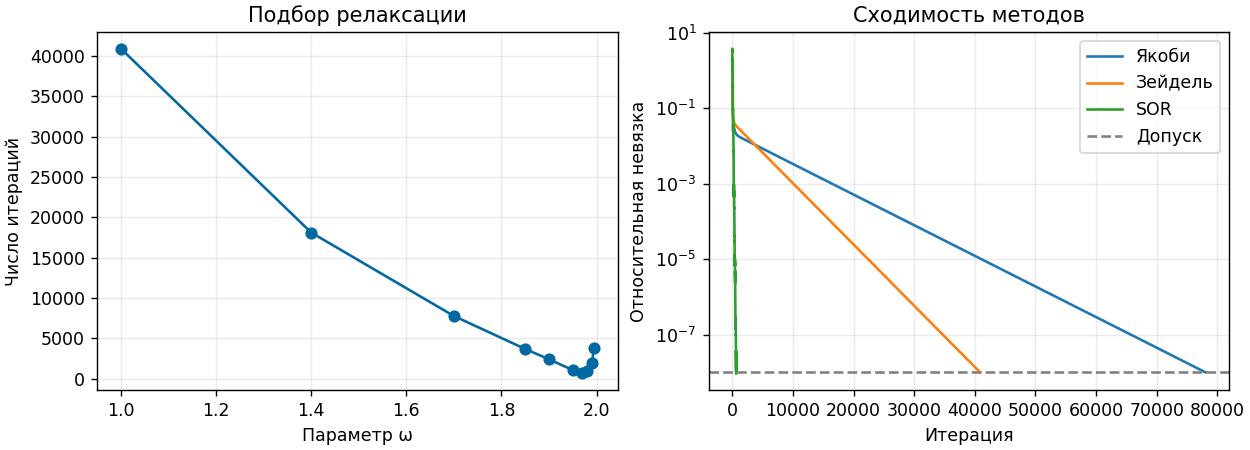

In [6]:
faces = cases['Верхняя']
h, d, b, power, parity = make_grid(N, faces, alpha)
omegas = np.array([1.0, 1.4, 1.7, 1.85, 1.90, 1.95, 1.97, 1.98, 1.99, 1.995])
counts = []
for w in omegas:
    _, hist = sor(d, b, parity, omega=w, eps=eps)
    counts.append(len(hist))
best_w = float(omegas[np.argmin(counts)])
print(f'Лучший параметр в переборе: omega = {best_w:.2f}')

method_results = {}
for name, solver in [('Якоби', jacobi), ('Зейдель', seidel), ('SOR', sor)]:
    start = perf_counter()
    if name == 'SOR':
        u, hist = solver(d, b, parity, omega=best_w, eps=eps)
    else:
        u, hist = solver(d, b, parity, eps=eps)
    elapsed = perf_counter() - start
    method_results[name] = (u, hist, elapsed)
    print(f'{name:8s}: {len(hist):6d} ит., {elapsed:7.3f} с, r = {hist[-1]:.2e}')

ref = method_results['SOR'][0]
for name, (u, _, _) in method_results.items():
    print(f'Отличие {name} от SOR: {np.max(np.abs(u-ref)):.2e} °C')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
ax[0].plot(omegas, counts, 'o-', color='#0369a1')
ax[0].set(xlabel='Параметр ω', ylabel='Число итераций', title='Подбор релаксации')
for name, (_, hist, _) in method_results.items():
    ax[1].semilogy(np.arange(1, len(hist)+1), hist, label=name)
ax[1].axhline(eps, ls='--', color='gray', label='Допуск')
ax[1].set(xlabel='Итерация', ylabel='Относительная невязка', title='Сходимость методов')
ax[1].legend()
for axis in ax:
    axis.grid(alpha=.25)
plt.show()

## 6. Четыре варианта охлаждения

Геометрия, мощность, $\lambda$, температура воды, $\alpha$, сетка и допуск одинаковы.
Кроме температуры процессора выводим диапазон температур металлических стенок и тепловой баланс.
Эффективное тепловое сопротивление по максимальной температуре контакта:
$R=(T_{\max}-T_{\text{в}})/P$, К/Вт.

In [7]:
solutions = {}
print(f'Вода: {T_water:g} °C; alpha = {alpha:g} Вт/(м²·К)')
print(f'{"Охлаждение":22s} {"Tmax, °C":>10s} {"Tср, °C":>10s} {"R, К/Вт":>10s} {"Q, Вт":>10s}')
for name, faces in cases.items():
    h, d, b, power, parity = make_grid(N, faces, alpha)
    u, hist = sor(d, b, parity, omega=best_w, eps=eps)
    tmax, mean, flows = metrics(u, h, power, faces, alpha)
    walls = np.concatenate([wall_temperature(u,h,f,alpha).ravel() for f in faces])
    solutions[name] = {'u': u, 'h': h, 'power': power, 'tmax': tmax,
                       'mean': mean, 'flows': flows, 'wall_min': walls.min(), 'wall_max': walls.max()}
    qout = sum(flows.values())
    print(f'{name:22s} {tmax:10.3f} {mean:10.3f} {(tmax-T_water)/P:10.5f} {qout:10.5f}')
    print(f'  Стенки: {walls.min():.3f}...{walls.max():.3f} °C; среднее {walls.mean():.3f} °C')
    print('  По граням:', ', '.join(f'{f}: {q:.5f} Вт' for f, q in flows.items()))
    assert abs(power.sum()-P) < 1e-10
    assert abs(qout-P)/P < 1e-5, 'Нарушен тепловой баланс'
    assert u.min() >= -1e-5
    if np.isfinite(alpha):
        q_from_walls = alpha*h*h*np.sum(walls-T_water)
        assert abs(q_from_walls-qout)/P < 1e-10
        expected_mean = T_water + P/(alpha*len(faces)*L**2)
        assert abs(walls.mean()-expected_mean) < 1e-3

Вода: 20 °C; alpha = 2000 Вт/(м²·К)
Охлаждение               Tmax, °C    Tср, °C    R, К/Вт      Q, Вт
Верхняя                    86.743     84.491    0.33371  200.00000
  Стенки: 59.977...60.024 °C; среднее 60.000 °C
  По граням: z+: 200.00000 Вт
Одна боковая               81.956     78.794    0.30978  200.00000
  Стенки: 57.595...64.057 °C; среднее 60.000 °C
  По граням: x-: 200.00000 Вт
Две противоположные        56.256     53.682    0.18128  200.00000
  Стенки: 37.628...44.024 °C; среднее 40.000 °C
  По граням: x-: 100.00000 Вт, x+: 100.00000 Вт
Две соседние               58.208     55.254    0.19104  200.00000
  Стенки: 35.337...44.616 °C; среднее 40.000 °C
  По граням: x-: 100.00000 Вт, y-: 100.00000 Вт


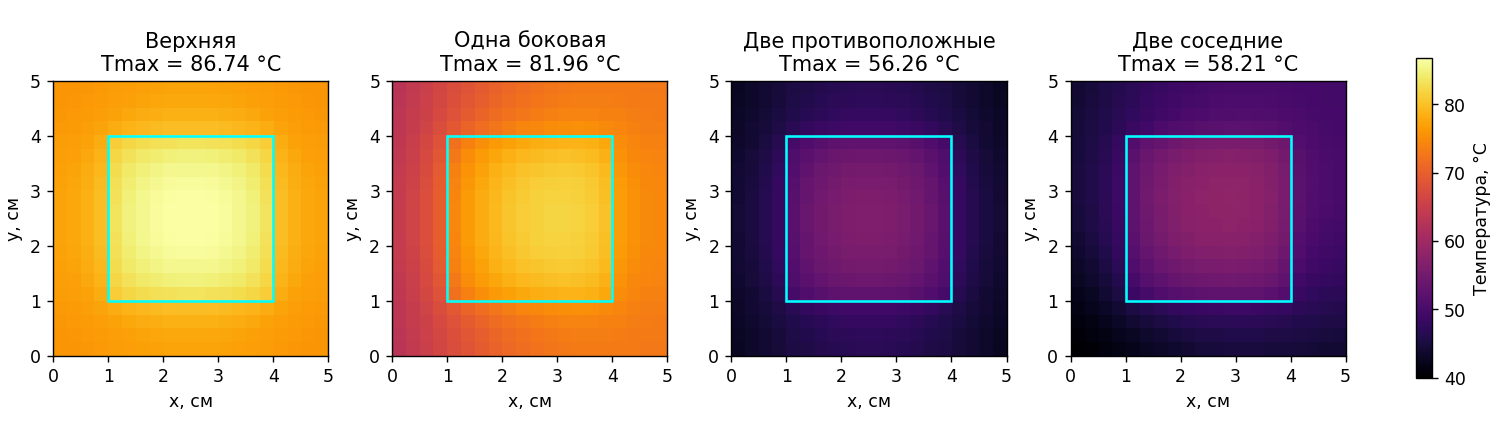

In [8]:
# Карты температуры поверхности контакта. Масштаб цвета общий.
limits = [min(contact_temperature(s['u'],s['h'],s['power']).min() for s in solutions.values()),
          max(s['tmax'] for s in solutions.values())]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout='constrained')
for ax, (name, sol) in zip(axes, solutions.items()):
    contact = contact_temperature(sol['u'], sol['h'], sol['power'])
    im = ax.imshow(contact.T, origin='lower', extent=[0,L*100,0,L*100],
                   cmap='inferno', vmin=limits[0], vmax=limits[1], interpolation='nearest')
    ax.add_patch(plt.Rectangle(((L-a)*50,(L-a)*50), a*100, a*100,
                              fill=False, edgecolor='cyan', linewidth=1.5))
    ax.set(title=f"{name}\nTmax = {sol['tmax']:.2f} °C", xlabel='x, см', ylabel='y, см')
fig.colorbar(im, ax=axes, shrink=.75, label='Температура, °C')
plt.show()

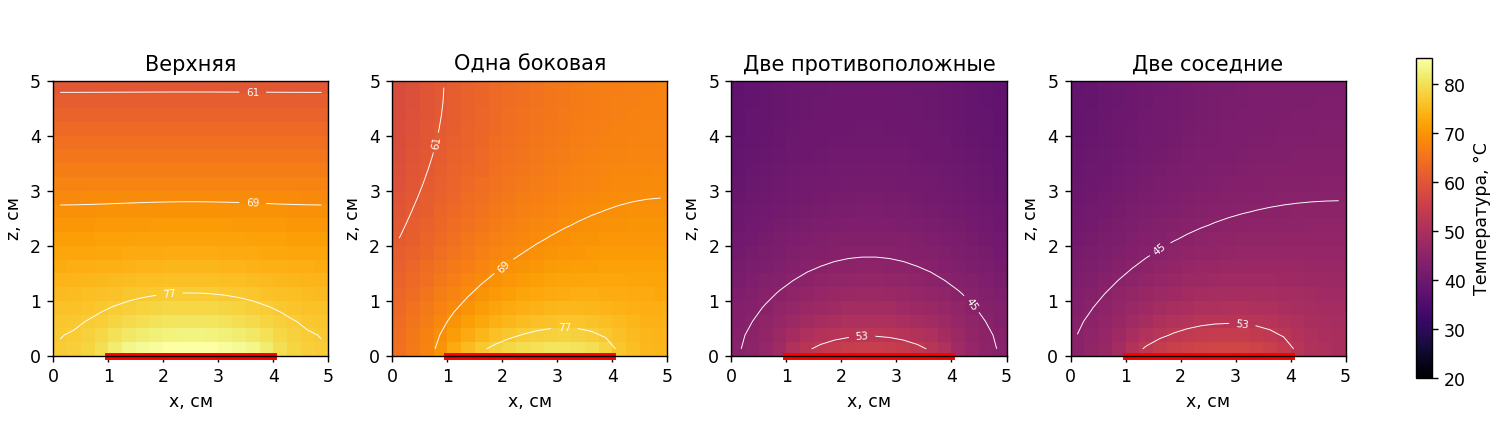

In [9]:
# Вертикальное сечение y ≈ L/2. Цвет и линии одинаковы для всех вариантов.
# При чётном N плоскость проходит через ближайший к центру слой ячеек.
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), layout='constrained')
vmin, vmax = T_water, max(T_water+s['u'].max() for s in solutions.values())
levels = np.linspace(vmin, vmax, 9)
for ax, (name, sol) in zip(axes, solutions.items()):
    x = (np.arange(N)+.5)*sol['h']*100
    section = T_water + sol['u'][:, N//2, :].T
    im = ax.pcolormesh(x, x, section, cmap='inferno', vmin=vmin, vmax=vmax, shading='nearest')
    lines = ax.contour(x, x, section, levels=levels[1:-1], colors='white', linewidths=.55)
    ax.clabel(lines, fontsize=6, fmt='%.0f')
    ax.plot([(L-a)*50,(L+a)*50], [0,0], color='red', lw=4, clip_on=False)
    ax.set(xlim=(0,L*100), ylim=(0,L*100), title=name, xlabel='x, см', ylabel='z, см', aspect='equal')
fig.colorbar(im, ax=axes, shrink=.75, label='Температура, °C')
plt.show()

## 7. Проверка по точному решению и предельному случаю

Пусть процессор равномерно нагревает всю нижнюю грань, а теплообмен с водой идёт только через верхнюю.
Решение одномерное:
$$\boxed{T(z)=T_{\text{в}}+\frac{P}{\alpha L^2}+\frac{P}{\lambda L^2}(L-z)}.$$
На верхней стенке $T(L)=T_{\text{в}}+P/(\alpha L^2)$, а через неё уходит мощность $P$.
Это проверяет одновременно теплопроводность, условие Робина и восстановление температуры стенки.

При $\alpha\to\infty$ должно получаться прежнее решение с заданной температурой верхней грани.
Проверяем конечный $\alpha$, большое $\alpha$ и точный предел в коде через `np.inf`.

In [10]:
for test_alpha in [alpha, 1e10, np.inf]:
    n_test = 10
    h, d, b, power, parity = make_grid(n_test, ['z+'], test_alpha)
    power[:] = P/n_test**2
    b[:] = 0
    b[:, :, 0] = power/(lam*h)
    u, hist = sor(d, b, parity, omega=1.9, eps=1e-11)
    z = (np.arange(n_test)+.5)*h
    exact = P/(test_alpha*L**2) + P/(lam*L**2)*(L-z)
    error = np.max(np.abs(u-exact[None,None,:]))
    surface = contact_temperature(u,h,power)
    exact_surface = T_water+P/(test_alpha*L**2)+P/(lam*L)
    wall = wall_temperature(u,h,'z+',test_alpha)
    exact_wall = T_water+P/(test_alpha*L**2)
    print(f'alpha={test_alpha:g}: ошибка {error:.2e} °C; '
          f'контакт {surface.max():.8f} °C; стенка {wall.mean():.8f} °C')
    assert error < 1e-6
    assert np.max(np.abs(surface-exact_surface)) < 1e-6
    assert np.max(np.abs(wall-exact_wall)) < 1e-6

alpha=2000: ошибка 1.72e-10 °C; контакт 80.00000000 °C; стенка 60.00000000 °C
alpha=1e+10: ошибка 3.26e-11 °C; контакт 40.00000800 °C; стенка 20.00000800 °C
alpha=inf: ошибка 3.26e-11 °C; контакт 40.00000000 °C; стенка 20.00000000 °C


## 8. Сходимость по сетке

Используем $N=10,20,40$. В этих сетках края процессора совпадают с границами ячеек.
Проверяем температуры контакта, а не только малость невязки. Это разные проверки:
невязка показывает точность решения дискретной системы, измельчение сетки — влияние пространственной аппроксимации.
Из-за скачка теплового потока на краю нагревателя нельзя без проверки требовать второй порядок сходимости
во всей области. Для ускорения на новых сетках используем $\omega=1.97$; это не гарантированный оптимум.

N=10, Верхняя               : Tmax=86.82768 °C, Tср=84.99245 °C
N=10, Одна боковая          : Tmax=82.13053 °C, Tср=79.34499 °C
N=10, Две противоположные   : Tmax=56.36279 °C, Tср=54.23354 °C
N=10, Две соседние          : Tmax=58.43516 °C, Tср=55.79374 °C
N=20, Верхняя               : Tmax=86.74271 °C, Tср=84.49100 °C
N=20, Одна боковая          : Tmax=81.95590 °C, Tср=78.79352 °C
N=20, Две противоположные   : Tmax=56.25569 °C, Tср=53.68198 °C
N=20, Две соседние          : Tmax=58.20823 °C, Tср=55.25409 °C
N=40, Верхняя               : Tmax=86.72442 °C, Tср=84.32859 °C
N=40, Одна боковая          : Tmax=81.91421 °C, Tср=78.61861 °C
N=40, Две противоположные   : Tmax=56.23188 °C, Tср=53.50706 °C
N=40, Две соседние          : Tmax=58.15267 °C, Tср=55.08214 °C


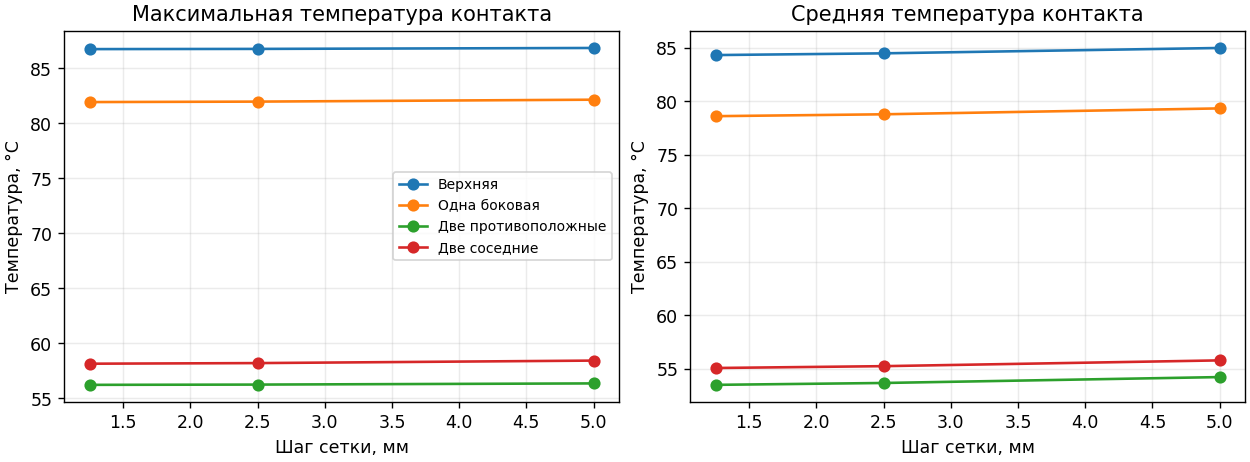

In [11]:
grid_sizes = [10, 20, 40]
grid_results = {name: [] for name in cases}
for n in grid_sizes:
    for name, faces in cases.items():
        if n == N:
            sol = solutions[name]
            tmax, mean = sol['tmax'], sol['mean']
        else:
            h, d, b, power, parity = make_grid(n, faces, alpha)
            u, hist = sor(d, b, parity, omega=1.97, eps=eps)
            tmax, mean, flows = metrics(u,h,power,faces,alpha)
            assert abs(sum(flows.values())-P)/P < 1e-5
        grid_results[name].append((tmax,mean))
        print(f'N={n:2d}, {name:22s}: Tmax={tmax:.5f} °C, Tср={mean:.5f} °C')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained')
steps_mm = L/np.array(grid_sizes)*1000
for name, values in grid_results.items():
    values = np.array(values)
    ax[0].plot(steps_mm, values[:,0], 'o-', label=name)
    ax[1].plot(steps_mm, values[:,1], 'o-', label=name)
for axis, title in zip(ax, ['Максимальная температура контакта', 'Средняя температура контакта']):
    axis.set(xlabel='Шаг сетки, мм', ylabel='Температура, °C', title=title)
    axis.grid(alpha=.25)
ax[0].legend(fontsize=8)
plt.show()

## 9. Результаты при выбранном коэффициенте теплоотдачи

In [12]:
print(f'alpha = {alpha:g} Вт/(м²·К), вода {T_water:g} °C')
print('Результаты на наиболее мелкой проверенной сетке N=40:')
for name, values in grid_results.items():
    print(f'{name:22s}: Tmax = {values[-1][0]:.2f} °C; '
          f'изменение относительно N=20: {abs(values[-1][0]-values[-2][0]):.3f} °C')
print('Лучший среди четырёх вариантов:', min(grid_results, key=lambda name: grid_results[name][-1][0]))

alpha = 2000 Вт/(м²·К), вода 20 °C
Результаты на наиболее мелкой проверенной сетке N=40:
Верхняя               : Tmax = 86.72 °C; изменение относительно N=20: 0.018 °C
Одна боковая          : Tmax = 81.91 °C; изменение относительно N=20: 0.042 °C
Две противоположные   : Tmax = 56.23 °C; изменение относительно N=20: 0.024 °C
Две соседние          : Tmax = 58.15 °C; изменение относительно N=20: 0.056 °C
Лучший среди четырёх вариантов: Две противоположные


Различия между вариантами охлаждения оцениваем по пересчитанным значениям выше.
Температура охлаждаемой стенки при конечном $\alpha$ превышает температуру воды.
У двух охлаждаемых граней суммарная площадь вдвое больше, чем у одной:
часть выигрыша связана с увеличением площади, а не только с её расположением.
Пары «верхняя / одна боковая» и «две противоположные / две соседние» сравниваются при одинаковой площади.

Малость невязки, выполнение теплового баланса, точное тестовое решение и исследование сетки
проверяют разные стороны расчёта. Три сетки показывают изменение результата, но не дают строгой оценки
ошибки непрерывного решения. Наибольшие градиенты возникают у участка нагрева.

При фиксированных $\lambda$, $\alpha$ и геометрии превышение температуры над температурой воды
пропорционально $P$. Зависимость от $\lambda$ уже не сводится к $1/\lambda$,
поскольку сопротивление теплоотдачи $1/\alpha$ остаётся самостоятельным слагаемым.

## 10. Влияние интенсивности теплообмена с водой

Меняем только $\alpha$, сохраняя температуру воды, геометрию и мощность процессора.
Все кривые рассчитываются на основной сетке $N$ (по умолчанию 20), поэтому их нельзя смешивать
с итоговыми значениями раздела 9 на более мелкой сетке.
Дополнительно рассчитываем предел $\alpha=\infty$ на той же сетке: это прежняя модель фиксированной
температуры стенок и нижняя граница температуры процессора для выбранного расположения охлаждения.
Ожидаем убывание температуры с ростом $\alpha$ и насыщение эффекта при достаточно большом $\alpha$.

Верхняя               : при alpha=500 — 206.74 °C; при alpha=16000 — 51.74 °C; предел — 46.74 °C
Одна боковая          : при alpha=500 — 202.01 °C; при alpha=16000 — 46.74 °C; предел — 41.52 °C
Две противоположные   : при alpha=500 — 116.40 °C; при alpha=16000 — 38.18 °C; предел — 35.09 °C
Две соседние          : при alpha=500 — 118.40 °C; при alpha=16000 — 39.99 °C; предел — 36.84 °C


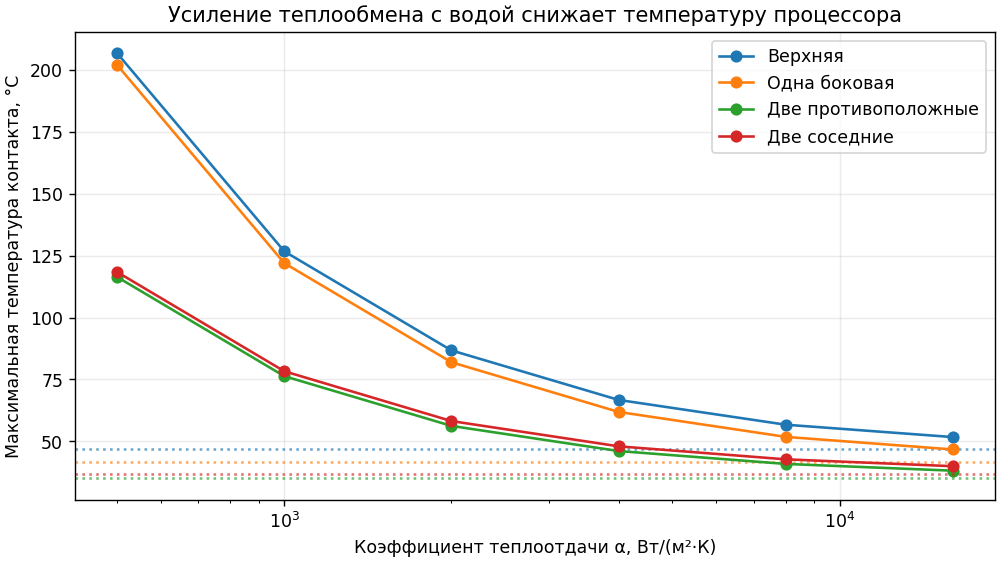

In [13]:
alpha_values = np.array([500., 1000., 2000., 4000., 8000., 16000.])
alpha_results, ideal_results = {}, {}
for name, faces in cases.items():
    values = []
    for value in alpha_values:
        if value == alpha:
            tmax = solutions[name]['tmax']
        else:
            h,d,b,power,parity = make_grid(N,faces,value)
            u,hist = sor(d,b,parity,omega=1.97,eps=eps)
            tmax,mean,flows = metrics(u,h,power,faces,value)
            assert abs(sum(flows.values())-P)/P < 1e-5
        values.append(tmax)
    h,d,b,power,parity = make_grid(N,faces,np.inf)
    u,hist = sor(d,b,parity,omega=1.97,eps=eps)
    ideal_results[name] = metrics(u,h,power,faces,np.inf)[0]
    alpha_results[name] = np.array(values)
    assert np.all(np.diff(values) < 0), 'Температура должна убывать с alpha'
    assert np.min(values) >= ideal_results[name]-1e-4
    print(f'{name:22s}: при alpha=500 — {values[0]:.2f} °C; '
          f'при alpha=16000 — {values[-1]:.2f} °C; предел — {ideal_results[name]:.2f} °C')

fig,ax = plt.subplots(figsize=(8,4.5),layout='constrained')
for name,values in alpha_results.items():
    line, = ax.semilogx(alpha_values,values,'o-',label=name)
    ax.axhline(ideal_results[name],color=line.get_color(),ls=':',alpha=.65)
ax.set(xlabel='Коэффициент теплоотдачи α, Вт/(м²·К)',
       ylabel='Максимальная температура контакта, °C',
       title='Усиление теплообмена с водой снижает температуру процессора')
ax.grid(alpha=.25)
ax.legend()
plt.show()

Пунктирные горизонтали — пределы при $\alpha\to\infty$ для соответствующих цветов.
Рост $\alpha$ уменьшает перепад «стенка — вода», но сохраняет перепад внутри металла.
Здесь мощность теплоотвода во всех установившихся режимах остаётся равной $P=200$ Вт;
меняется температура, при которой достигается этот теплоотвод.

**Параметры исследования** находятся в первой ячейке: `T_water` — температура воды,
`alpha` — коэффициент теплоотдачи; также можно менять `P`, `L`, `a`, `lam`, `N`.
После изменения параметров следует заново выполнить все ячейки сверху вниз.
Для меньших $\alpha$ и более мелких сеток итерации могут заметно замедляться.